# Intelligent Financial Fraud Detection

I built a transaction scorer and a review queue for the ULB dataset. This notebook puts the full workflow in one run, from checking gradients to exporting flagged transactions. In Colab, **Runtime → Run all** runs the experiment. An empty `incoming_csv` replays the held-out window. A custom batch needs the same 30 ULB inputs.

In [1]:
from pathlib import Path
from importlib.util import find_spec

project_folder = "Colab Notebooks/Project 01: Intelligent Financial Fraud Detection" # @param {type:"string"}
incoming_csv = "" # @param {type:"string"}
if find_spec("google") and find_spec("google.colab"):
    from google.colab import drive
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive") / project_folder
else:
    project = Path.cwd()
project.mkdir(parents=True, exist_ok=True)
csv_path = project / "Dataset" / "creditcard.csv"
if not csv_path.is_file():
    import kagglehub
    csv_path = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud")) / "creditcard.csv"
print("Dataset:", csv_path.name)

Mounted at /content/drive
Dataset: creditcard.csv


## Checking my backpropagation calculation

For a batch of $n$ rows, $D=(p-y)/n$ is the output-logit gradient. The output-weight gradient is $H^TD$, and the hidden error is $(DW_2^T)(1-H^2)$ for tanh. I check the analytical gradients against finite differences before using gradient descent.

In [2]:
"""Learn backpropagation on four invented transactions. Run with Python and NumPy."""

import numpy as np


# Columns are two fictional binary transaction signals. The label is 1 when
# exactly one signal is active. This interaction needs a nonlinear boundary.
X = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y = np.array([[0.], [1.], [1.], [0.]])


def forward(params):
    hidden = np.tanh(X @ params["W1"] + params["b1"])
    logits = hidden @ params["W2"] + params["b2"]
    scores = np.exp(-np.logaddexp(0., -logits))  # stable sigmoid
    loss = np.mean(np.logaddexp(0., logits) - y * logits)
    return hidden, scores, loss


def backward(params, hidden, scores):
    # Mean binary cross-entropy contributes one factor of 1 / batch size.
    d_logits = (scores - y) / len(X)
    d_hidden = d_logits @ params["W2"].T
    d_pre_activation = d_hidden * (1. - hidden**2)
    return {
        "W2": hidden.T @ d_logits,
        "b2": d_logits.sum(axis=0),
        "W1": X.T @ d_pre_activation,
        "b1": d_pre_activation.sum(axis=0),
    }


def check_gradients(params, gradients):
    # Perturb each parameter and measure the slope of the actual loss.
    step = 1e-5
    largest_error = 0.
    for name, values in params.items():
        for index in np.ndindex(values.shape):
            original = values[index]
            values[index] = original + step
            plus = forward(params)[2]
            values[index] = original - step
            minus = forward(params)[2]
            values[index] = original
            measured = (plus - minus) / (2 * step)
            largest_error = max(largest_error, abs(measured - gradients[name][index]))
            np.testing.assert_allclose(measured, gradients[name][index], atol=1e-7)
    return largest_error


def main():
    rng = np.random.default_rng(42)
    params = {
        "W1": rng.normal(size=(2, 4)),
        "b1": np.zeros(4),
        "W2": rng.normal(size=(4, 1)),
        "b2": np.zeros(1),
    }
    hidden, scores, initial_loss = forward(params)
    error = check_gradients(params, backward(params, hidden, scores))
    print(f"Largest gradient-check error = {error:.2e}")
    for _ in range(2000):
        hidden, scores, _loss = forward(params)
        gradients = backward(params, hidden, scores)
        for name in params:
            params[name] -= 0.1 * gradients[name]

    _, scores, final_loss = forward(params)
    print(f"Mean training loss = {initial_loss:.4f} -> {final_loss:.4f}")
    print("Signals    Label    Learned score")
    for signals, label, score in zip(X.astype(int), y[:, 0], scores[:, 0]):
        print(f"{signals}      {int(label)}        {score:.3f}")

main()

Largest gradient-check error = 1.39e-11
Mean training loss = 0.8299 -> 0.0219
Signals    Label    Learned score
[0 0]      0        0.007
[0 1]      1        0.970
[1 0]      1        0.982
[1 1]      0        0.031


## The transaction data

I wanted to know whether a small ANN could catch more fraud than two tabular baselines at a reasonable review workload. Each row is one payment. The inputs are elapsed seconds (`Time`), transaction amount and 28 anonymized PCA components. `Class` is the label: 1 for fraud and 0 for legitimate. Only 492 of the 284,807 rows are frauds. Calling every payment legitimate would score 99.83% accuracy.

I use the Drive copy at `Dataset/creditcard.csv`, with KaggleHub as a fallback. [ULB dataset card](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

In [3]:
import copy
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve, auc,
                             confusion_matrix, precision_score, recall_score)
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# These 30 columns will be known at scoring time. Class is the answer used to teach the model.
features = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount"]
df = pd.read_csv(csv_path, usecols=features + ["Class"]).sort_values("Time", kind="stable")
if not np.isfinite(df.to_numpy()).all() or set(df.Class.unique()) != {0, 1}:
    raise ValueError("Expected finite ULB features and binary labels 0 and 1.")
print(f"{len(df):,} transactions | {device} runtime")

284,807 transactions | cuda runtime


## Splitting by transaction time

I train on earlier payments and evaluate on later ones. I keep equal timestamps together and fit the scaler on training rows so future transactions cannot affect the training statistics.

In [4]:
times = df.Time.to_numpy()
# Choose cutoffs by row position, then split by time so equal timestamps stay together.
cut1, cut2 = times[[int(.70 * len(df)), int(.85 * len(df))]]
train = df[df.Time < cut1]
valid = df[(df.Time >= cut1) & (df.Time < cut2)]
test = df[df.Time >= cut2]
for name, part in [("train", train), ("validation", valid), ("test", test)]:
    if part.Class.nunique() != 2:
        raise ValueError(f"{name} needs both classes for evaluation.")
print(train.Class.value_counts().rename("training transactions"))
print(f"Always predicting legitimate yields training accuracy {1 - train.Class.mean():.2%}.")
# Learn the average and spread of each input from past transactions only.
scaler = StandardScaler().fit(train[features])

def arrays(part):
    # Apply those same training statistics to each window. X holds inputs and y holds labels.
    return scaler.transform(part[features]).astype("float32"), part.Class.to_numpy(dtype="int64")

Xtr, ytr = arrays(train)
Xv, yv = arrays(valid)

Class
0    198980
1       384
Name: training transactions, dtype: int64
Always predicting legitimate yields training accuracy 99.81%.


## Training with rare positives

I use the same 64–32 ANN and class-weighted loss as the reference model. This version stops after three epochs without a better validation AP. The checkpoint and cutoff below belong to this run.

In [5]:
model = nn.Sequential(nn.Linear(len(features), 64), nn.ReLU(), nn.Dropout(0.2),
                      nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)).to(device)
# For each fraud example, count how many legitimate examples there are in the training set.
ratio = float((ytr == 0).sum() / ytr.sum())
# Scale the positive-label loss by this ratio so rare frauds contribute more to the update.
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(ratio, device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
dataset = TensorDataset(torch.from_numpy(Xtr), torch.tensor(ytr, dtype=torch.float32))
loader = DataLoader(dataset, batch_size=512, shuffle=True)

@torch.inference_mode()
def ann_scores(x):
    model.eval()
    chunks = torch.from_numpy(x).split(4096)
    return torch.cat([model(c.to(device)).flatten().sigmoid().cpu() for c in chunks]).numpy()

best_ap = -1.
for epoch in range(1, 16):
    model.train()
    total_loss = 0.
    for inputs, labels in loader:
        # Clear gradients from the previous update. PyTorch adds new gradients to any already stored.
        optimizer.zero_grad()
        # Flatten [batch size, 1] to match the one-dimensional fraud labels.
        logits = model(inputs.to(device)).flatten()
        loss = loss_fn(logits, labels.to(device))
        loss.backward()
        optimizer.step()
        # Weight each batch mean by its row count so a short final batch counts proportionally.
        total_loss += loss.item() * len(labels)
    # Use validation labels to check how well the model ranks frauds across thresholds.
    ap = average_precision_score(yv, ann_scores(Xv))
    print(f"Epoch {epoch:2d} | training loss {total_loss / len(dataset):.4f} | validation AP {ap:.4f}")
    if ap > best_ap:
        best_ap, best_epoch = ap, epoch
        # Keep a separate copy of this epoch's weights while training continues.
        best_weights = copy.deepcopy(model.state_dict())
    # Patience is measured in epochs since the best validation AP.
    if epoch - best_epoch >= 3:
        break
model.load_state_dict(best_weights)
print(f"Restored epoch {best_epoch}")

Epoch  1 | training loss 0.5214 | validation AP 0.8249
Epoch  2 | training loss 0.2960 | validation AP 0.7983
Epoch  3 | training loss 0.2477 | validation AP 0.8477
Epoch  4 | training loss 0.2343 | validation AP 0.7993
Epoch  5 | training loss 0.2118 | validation AP 0.8194
Epoch  6 | training loss 0.2009 | validation AP 0.8501
Epoch  7 | training loss 0.1944 | validation AP 0.7577
Epoch  8 | training loss 0.1577 | validation AP 0.7715
Epoch  9 | training loss 0.1705 | validation AP 0.7702
Restored epoch 6


## Choosing a cutoff for each model

The ANN, logistic regression and boosted trees have different score scales. I chose the cutoff that maximized each model’s validation F1, then kept those cutoffs for the test window.

In [6]:
# Compare the ANN with a linear classifier and a model that combines many small trees.
baselines = {
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=500),
    "Boosted trees": HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                                     max_iter=100, random_state=SEED),
}
validation = {"ANN": ann_scores(Xv)}
for name, estimator in baselines.items():
    estimator.fit(Xtr, ytr)
    # Column 1 holds the score for the fraud class. Keep one score per validation row.
    validation[name] = estimator.predict_proba(Xv)[:, 1]

def choose_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    # The last precision-recall point has no threshold. Compare F1 only at actual cutoffs.
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[f1.argmax()])

# Freeze one cutoff per model before evaluating any test predictions.
thresholds = {name: choose_threshold(yv, scores) for name, scores in validation.items()}
display(pd.Series(thresholds, name="validation threshold"))

,validation threshold
ANN,0.999155
Logistic regression,0.999993
Boosted trees,0.781576


In [7]:
def alert_counts(labels, scores, threshold):
    # Lowering the cutoff sends more transactions to the review queue, including possible false alarms.
    flags = scores >= threshold
    # FP is a legitimate transaction flagged for review. FN is a fraud the model missed.
    tn, fp, fn, tp = confusion_matrix(labels, flags, labels=[0, 1]).ravel()
    return {"Alerts": int(flags.sum()), "True alerts": tp, "False alerts": fp, "Missed fraud": fn,
            "Precision": precision_score(labels, flags, zero_division=0),
            "Recall": recall_score(labels, flags, zero_division=0)}

## Reviewing the validation queue

I can change the cutoff here and see the effect on precision, recall and investigation volume. The final export uses the validation-selected operating cutoff.

In [8]:
threshold = thresholds["ANN"]
scores = validation["ANN"]
labels = yv
curve_precision, curve_recall, _ = precision_recall_curve(labels, scores)
validation_rows = valid[["Time", "Amount", "Class"]].assign(score=scores)

,Reviews,Fraud caught,False alerts,Missed fraud,Precision,Recall
Saved cutoff,46,43,3,13,0.9348,0.7679
Selected cutoff,46,43,3,13,0.9348,0.7679


Selected cutoff = 0.9991548061


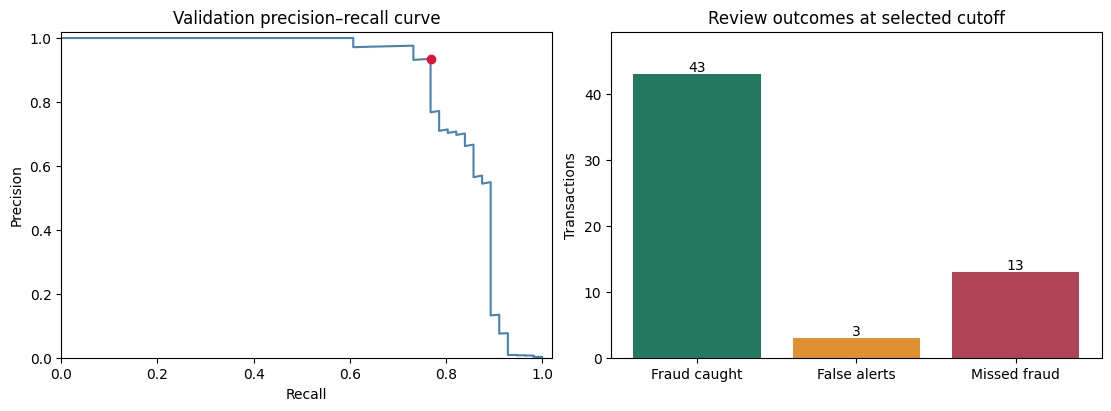

,Time,Amount,score,Class
234574,148028.000000,0.00,0.999999881,1
238222,149582.000000,1.10,0.999999881,1
230076,146179.000000,0.77,0.999999762,1
223618,143456.000000,1.00,0.999999046,1
223572,143434.000000,1.00,0.999998569,1
226814,144808.000000,667.55,0.999998331,1
235634,148476.000000,0.76,0.999997854,1
229712,146022.000000,1.18,0.999997735,1
235644,148479.000000,122.68,0.999995351,1
203700,134928.000000,0.00,0.999994278,1


In [9]:
# @title Validation dashboard
use_saved_threshold = True # @param {type:"boolean"}
custom_cutoff = 0.999 # @param {type:"number"}
cutoff = threshold if use_saved_threshold else custom_cutoff
if not 0 <= cutoff <= 1:
    raise ValueError("Enter a cutoff between 0 and 1.")

def review_summary(cut):
    # A transaction at the exact cutoff is included in the queue.
    flagged = scores >= cut
    tp = int(((labels == 1) & flagged).sum())
    fp = int(flagged.sum()) - tp
    fn = int(labels.sum()) - tp
    return {"Reviews": tp + fp, "Fraud caught": tp, "False alerts": fp, "Missed fraud": fn,
            "Precision": tp / (tp + fp) if tp + fp else np.nan, "Recall": tp / (tp + fn)}

current = review_summary(cutoff)
display(pd.DataFrame([review_summary(threshold), current], index=["Saved cutoff", "Selected cutoff"]).round(4))
print(f"Selected cutoff = {cutoff:.10f}")

fig, (pr, counts) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
pr.plot(curve_recall, curve_precision, color="steelblue")
if current["Reviews"]:
    pr.scatter(current["Recall"], current["Precision"], color="crimson", zorder=3)
pr.set(xlabel="Recall", ylabel="Precision", title="Validation precision–recall curve",
       xlim=(0, 1.02), ylim=(0, 1.02))
categories = ["Fraud caught", "False alerts", "Missed fraud"]
bars = counts.bar(categories, [current[key] for key in categories], color=["#237a61", "#df9132", "#ae4456"])
counts.bar_label(bars)
counts.margins(y=0.15)
counts.set(ylabel="Transactions", title="Review outcomes at selected cutoff")
plt.show()

# Ground truth is shown here for retrospective review.
queue = validation_rows.loc[validation_rows.score >= cutoff, ["Time", "Amount", "score", "Class"]]
display(queue.nlargest(10, "score").style.format({"score": "{:.9f}", "Amount": "{:.2f}"}))

## Performance on later transactions

I compared both ranking quality and the decisions at the chosen cutoff. The PR-AUC column uses trapezoidal integration. AP summarizes the same precision–recall points with different weighting.

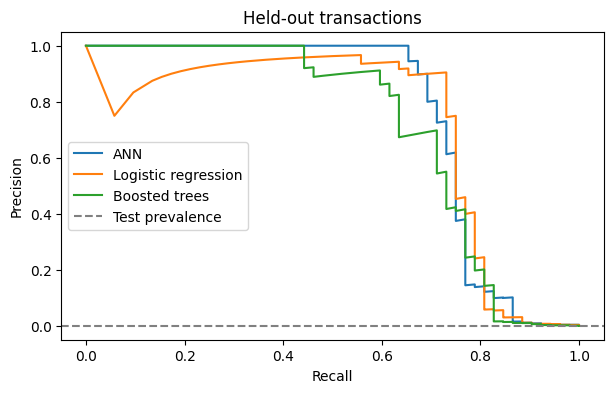

,Threshold,AP,PR-AUC,Alerts,True alerts,False alerts,Missed fraud,Precision,Recall
Model,,,,,,,,,
ANN,0.9992,0.7512,0.7508,35,34,1,18,0.9714,0.6538
Logistic regression,1.0000,0.7069,0.7104,35,33,2,19,0.9429,0.6346
Boosted trees,0.7816,0.7068,0.7058,40,33,7,19,0.8250,0.6346


In [10]:
Xt, yt = arrays(test)
test_scores = {"ANN": ann_scores(Xt)}
for name, estimator in baselines.items():
    test_scores[name] = estimator.predict_proba(Xt)[:, 1]

rows = []
fig, ax = plt.subplots(figsize=(7, 4))
for name, scores in test_scores.items():
    # Trace the tradeoff between correct alerts (precision) and fraud coverage (recall).
    p, r, _ = precision_recall_curve(yt, scores)
    rows.append({"Model": name, "Threshold": thresholds[name], "AP": average_precision_score(yt, scores),
                 "PR-AUC": auc(r, p), **alert_counts(yt, scores, thresholds[name])})
    ax.plot(r, p, label=name)
# The fraud fraction gives a reference precision for random ranking.
ax.axhline(yt.mean(), ls="--", color="gray", label="Test prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Held-out transactions")
ax.legend()
plt.show()
display(pd.DataFrame(rows).set_index("Model").round(4))

## A fixed review budget

I use the number of validation alerts at this run’s cutoff as the budget and compared two ways to fill them: highest score first, or largest amount among a shortlist twice the size of that budget. Both queues are selected before I look at the fraud labels.

In [11]:
ranked = validation_rows.assign(source_record=validation_rows.index + 1).sort_values(
    ["score", "source_record"], ascending=[False, True])
budget = int(ranked.score.ge(threshold).sum())
queues = {"Score order": ranked.head(budget),
          "Amount within high risk": ranked.head(2 * budget).sort_values(
              ["Amount", "score", "source_record"], ascending=[False, False, True]).head(budget)}
policy_rows = []
for policy, queue in queues.items():
    caught = queue[queue.Class.eq(1)]
    policy_rows.append({"Policy": policy, "Reviews": len(queue), "Frauds": len(caught),
                        "False alerts": len(queue) - len(caught), "Fraud amount": caught.Amount.sum()})
policies = pd.DataFrame(policy_rows)
display(policies)

,Policy,Reviews,Frauds,False alerts,Fraud amount
0,Score order,46,43,3,7984.62
1,Amount within high risk,46,24,22,8214.64


## Batch scoring and missed cases

I export the full scored batch and a ranked review queue, then inspect missed frauds on the held-out labels. Each run gets a separate directory containing its weights, threshold, split metadata, metrics and CSVs.

In [12]:
from datetime import datetime, timezone
from tempfile import TemporaryDirectory
from uuid import uuid4
import csv
import json
import sklearn

if incoming_csv.strip():
    with Path(incoming_csv).open(encoding="utf-8-sig", newline="") as stream:
        header = next(csv.reader(stream), [])
    if len(set(header)) != len(header):
        raise ValueError("Duplicate CSV headers.")
    batch = pd.read_csv(incoming_csv, usecols=features, dtype="float64")
    if batch.empty or not np.isfinite(batch[features].to_numpy()).all():
        raise ValueError("Scoring requires at least one row with finite numeric inputs.")
    scaled = scaler.transform(batch[features]).astype("float32")
    if not np.isfinite(scaled).all():
        raise ValueError("Input exceeds the ANN numeric range.")
    batch_scores = ann_scores(scaled)
else:
    batch, batch_scores = test, test_scores["ANN"]

scored = batch[["Time", "Amount"]].assign(source_record=batch.index + 1,
    risk_score=batch_scores.astype("float64"), send_for_review=batch_scores >= threshold)
review = scored.loc[scored.send_for_review].sort_values(["risk_score", "source_record"], ascending=[False, True])
audit = test[["Time", "Amount", "Class"]].assign(source_record=test.index + 1, risk_score=test_scores["ANN"])
misses = audit.loc[audit.Class.eq(1) & audit.risk_score.lt(threshold)].sort_values("Amount", ascending=False)
print(f"Export batch: {len(scored):,} transactions, {len(review):,} alerts")
print(f"Held-out frauds missed: {len(misses)}, totaling {misses.Amount.sum():,.2f}")
display(misses.head(5))

Export batch: 42,724 transactions, 35 alerts
Held-out frauds missed: 18, totaling 2,787.71


,Time,Amount,Class,source_record,risk_score
249239,154309.0,1096.99,1,249240,0.543805
275992,166831.0,634.30,1,275993,0.707282
245556,152802.0,357.95,1,245557,0.539714
258403,158638.0,296.00,1,258404,0.998793
254344,156685.0,187.11,1,254345,0.033146


In [13]:
# Publish completed files together under a fresh run ID.
output = project / "Artifacts" / "End-to-end runs"
output.mkdir(parents=True, exist_ok=True)
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
destination = output / run_id
with TemporaryDirectory(dir=output) as temp:
    staging = Path(temp) / "results"
    staging.mkdir()
    torch.save({"state_dict": {k: v.cpu() for k, v in best_weights.items()},
                "features": features, "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
                "threshold": threshold, "best_epoch": best_epoch,
                "architecture": "Linear(30,64) ReLU Dropout(0.2) Linear(64,32) ReLU Linear(32,1)"},
               staging / "ann.pt")
    pd.DataFrame(rows).to_csv(staging / "test_metrics.csv", index=False)
    policies.to_csv(staging / "validation_policies.csv", index=False)
    scored.to_csv(staging / "scored_transactions.csv", index=False)
    review.to_csv(staging / "review_queue.csv", index=False)
    misses.to_csv(staging / "missed_frauds.csv", index=False)
    manifest = {"run_id": run_id, "seed": SEED, "best_epoch": best_epoch,
                "ann_threshold": threshold, "batch_source": Path(incoming_csv).name if incoming_csv.strip() else "held-out replay",
                "split_sizes": [len(train), len(valid), len(test)], "time_boundaries": [float(cut1), float(cut2)],
                "torch": str(torch.__version__), "sklearn": sklearn.__version__, "numpy": np.__version__,
                "pandas": pd.__version__}
    (staging / "run.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    staging.rename(destination)
print("Saved under Artifacts / End-to-end runs /", run_id)

Saved under Artifacts / End-to-end runs / 20261121T185029Z_0ac93d0a
